# Задание 4.10
## Случайный отрезок в круге

### Условие:
В круге радиуса 1 наудачу выбирается отрезок. Найти вероятность того, что длина этого отрезка будет меньше радиуса круга.

### Модель (важно уточнить, что значит «наудачу выбирается отрезок»):
Отрезок задаётся двумя концами; будем считать, что **оба конца независимо выбираются наудачу (равномерно) в круге** $D=\{|z|\le1\}$. (Ответ из листка $1-\frac{3\sqrt3}{4\pi}$ получается именно в этой модели. Если выбирать концы равномерно на *окружности*, получится другой ответ — см. замечание про парадокс Бертрана в конце.)

### Решение:
Пусть первый конец $z_1$ находится на расстоянии $r=|z_1|$ от центра. Второй конец лежит ближе 1 к $z_1$ тогда и только тогда, когда он попадает в круг $B(z_1,1)$ радиуса 1 с центром $z_1$. Значит, **условная** вероятность равна доле площади единичного круга $D$, лежащей в $B(z_1,1)$:
$$\mathbb P(|z_1-z_2|<1\mid z_1)=\frac{S_{\rm линзы}(r)}{\pi},$$
где линза — пересечение двух кругов радиуса 1 с расстоянием между центрами $r$. Площадь линзы двух равных кругов радиуса 1:
$$S(r)=2\arccos\frac r2-\frac r2\sqrt{4-r^2}.$$
Плотность $r$ для равномерной точки в круге: $2r\,dr$ ($P(|z_1|<r)=r^2$). По формуле полной вероятности
$$\mathbb P=\int_0^1\frac{S(r)}{\pi}\,2r\,dr=\frac2\pi\int_0^1 r\Bigl(2\arccos\frac r2-\frac r2\sqrt{4-r^2}\Bigr)dr .$$
**Вычисление.** 
(1) По частям: $\displaystyle\int_0^12r\arccos\frac r2dr=\Bigl[r^2\arccos\frac r2\Bigr]_0^1+\int_0^1\frac{r^2}{\sqrt{4-r^2}}dr=\frac\pi3+\Bigl(\frac\pi3-\frac{\sqrt3}2\Bigr)=\frac{2\pi}3-\frac{\sqrt3}2$ (последний интеграл — подстановка $r=2\sin\varphi$: $4\!\int_0^{\pi/6}\!\sin^2\varphi\,d\varphi=\frac\pi3-\frac{\sqrt3}2$).
(2) $\displaystyle\int_0^1\frac{r^2}{2}\sqrt{4-r^2}\,dr$ при $r=2\sin\varphi$ равен $\int_0^{\pi/6}(1-\cos4\varphi)d\varphi=\frac\pi6-\frac{\sqrt3}8$.
Тогда $\displaystyle\int_0^1rS(r)\,dr=\frac{2\pi}3-\frac{\sqrt3}2-\frac\pi6+\frac{\sqrt3}8=\frac\pi2-\frac{3\sqrt3}8$ и
$$\mathbb P=\frac2\pi\Bigl(\frac\pi2-\frac{3\sqrt3}8\Bigr)=1-\frac{3\sqrt3}{4\pi}\approx0{,}5865033 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка (`sympy`/численно): формула площади линзы и значение интеграла

In [2]:
import sympy as sp

# 1) формула площади линзы: проверим Монте-Карло при r = 0.7 (доля точек единичного круга с центром 0, лежащих в круге с центром (0.7, 0))
r0, M = 0.7, 2_000_000
ang = 2*np.pi*rng.random(M); rad = np.sqrt(rng.random(M))
inside = np.hypot(rad*np.cos(ang) - r0, rad*np.sin(ang)) < 1
lens = lambda r: 2*np.arccos(r/2) - r/2*np.sqrt(4 - r**2)
print(f'площадь линзы при r = {r0}: формула {lens(r0):.5f},  Монте-Карло {np.pi*inside.mean():.5f}')

# 2) значение интеграла (2/π)∫ r·S(r) dr на [0, 1]
r = sp.symbols('r', positive=True)
S = 2*sp.acos(r/2) - r/2*sp.sqrt(4 - r**2)
val = sp.Integral(2/sp.pi*r*S, (r, 0, 1)).evalf(25)
exact = 1 - 3*sp.sqrt(3)/(4*sp.pi)
print('интеграл (численно, 25 знаков) =', val)
print('1 − 3√3/(4π)                   =', exact.evalf(25))
P_exact = float(exact)

площадь линзы при r = 0.7: формула 1.77073,  Монте-Карло 1.76792
интеграл (численно, 25 знаков) = 0.5865033284336559628665051
1 − 3√3/(4π)                   = 0.5865033284336559628665051


### Моделирование: $N=10^6$ случайных отрезков (оба конца равномерно в круге)

In [3]:
N = 1_000_000
def random_point_in_disk(n):
    # равномерная точка в единичном круге: радиус √U, угол равномерный (иначе точки скапливались бы у центра)
    return np.sqrt(rng.random(n)), 2*np.pi*rng.random(n)
r1, f1 = random_point_in_disk(N); r2, f2 = random_point_in_disk(N)
length = np.hypot(r1*np.cos(f1) - r2*np.cos(f2), r1*np.sin(f1) - r2*np.sin(f2))      # длина отрезка
hit = length < 1                                                                      # короче радиуса
print(f'N = {N}: p̂ = {hit.mean():.6f},  точное P = {P_exact:.6f}');  table(hit, P_exact)

# для сравнения: концы равномерно на ОКРУЖНОСТИ (парадокс Бертрана) — другая модель, другой ответ
a1, a2 = 2*np.pi*rng.random(N), 2*np.pi*rng.random(N)
chord = 2*np.abs(np.sin((a1 - a2)/2))
print(f'концы на окружности: P(длина < 1) ≈ {np.mean(chord < 1):.5f}  (теоретически 1/3)')

N = 1000000: p̂ = 0.586177,  точное P = 0.586503
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.6600000   7.35e-02   1.48e-01
     1000   0.5740000   1.25e-02   4.67e-02
    10000   0.5817000   4.80e-03   1.48e-02
   100000   0.5866600   1.57e-04   4.67e-03
  1000000   0.5861770   3.26e-04   1.48e-03
концы на окружности: P(длина < 1) ≈ 0.33338  (теоретически 1/3)


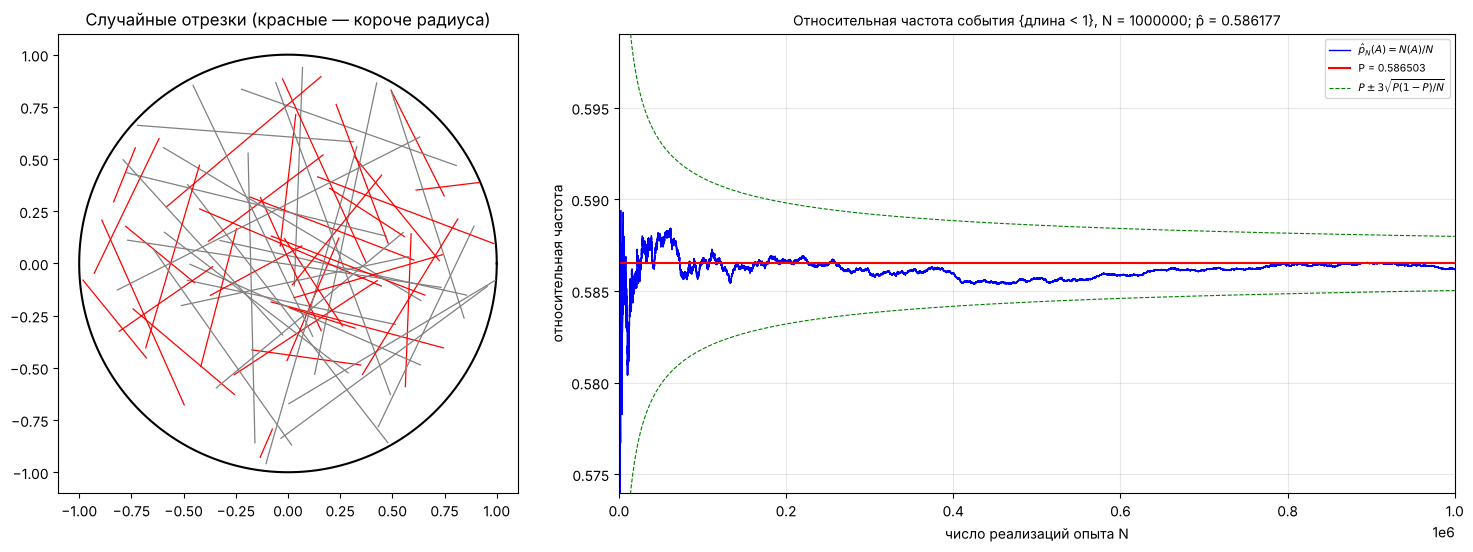

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1, 1.7]})
t = np.linspace(0, 2*np.pi, 400); axs[0].plot(np.cos(t), np.sin(t), 'k-')
for i in range(60):                                                                    # 60 первых отрезков; короткие — красные
    c = 'red' if hit[i] else 'gray'
    axs[0].plot([r1[i]*np.cos(f1[i]), r2[i]*np.cos(f2[i])], [r1[i]*np.sin(f1[i]), r2[i]*np.sin(f2[i])], '-', color=c, lw=0.9)
axs[0].set_aspect('equal'); axs[0].set_title('Случайные отрезки (красные — короче радиуса)')
plot_frequency(axs[1], hit, P_exact, f'Относительная частота события {{длина < 1}}, N = {N}; p̂ = {hit.mean():.6f}')
plt.tight_layout(); plt.savefig('task_4_10.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P=1-\dfrac{3\sqrt3}{4\pi}\approx0{,}5865033$ (оба конца отрезка выбираются равномерно в круге). 

**Замечание (парадокс Бертрана).** Фраза «наудачу выбирается отрезок» неоднозначна. Если концы выбирать равномерно на окружности, то длина хорды $<1$ при центральном угле $<60^\circ$ и вероятность равна $\frac13$ (проверено моделированием выше). Ответ из листка соответствует модели «два равномерных конца внутри круга».